# Priorización automática de baches a partir de fotos ciudadanas
**Inteligencia Artificial Avanzada · Proyecto integrador (Momento 3) · Ruta A · Tema libre**
Andrés Nicolás Sepúlveda Amaya · Fundación Universitaria Compensar

El notebook corre de principio a fin: descarga los datos, hace el EDA, separa train/val/test, entrena la línea base y dos redes profundas, evalúa, explica con Grad-CAM, analiza errores y genera los reportes en lenguaje natural.


In [21]:
import os, sys, json, glob, random, zipfile, urllib.request, time, datetime
import xml.etree.ElementTree as ET
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, recall_score, accuracy_score, confusion_matrix, classification_report
from skimage.feature import hog

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

SMOKE = os.environ.get("SMOKE") == "1"          # prueba rapida con datos sinteticos
PAISES = ["India"]                               # se puede agregar "Japan", "United_States"
IMG = 160 if not SMOKE else 64
BATCH = 32
EP_CNN, EP_TL1, EP_TL2 = (12, 6, 6) if not SMOKE else (1, 1, 1)
DATA = "datos"; OUT = "resultados"
os.makedirs(DATA, exist_ok=True); os.makedirs(OUT, exist_ok=True)
CLASES = ["baja", "media", "alta"]
R = {"fecha_ejecucion": datetime.datetime.now().isoformat(timespec="seconds"), "semilla": SEED, "paises": PAISES, "img": IMG}
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Datos
**Fuente:** RDD2022 (Arya et al.), publicado en figshare con licencia CC BY 4.0. El enlace oficial por país ya no responde y figshare bloquea descargas automáticas, así que se usa la copia derivada en Hugging Face (`akiii1234/RoadDamageDetection`, formato YOLO). La fecha de descarga queda en `resultados/resultados.json`.

In [23]:
import re, yaml, shutil
from huggingface_hub import hf_hub_download
z = hf_hub_download("akiii1234/RoadDamageDetection", "road_damage_dataset.zip", repo_type="dataset")
R["fuente_descarga"] = "Hugging Face akiii1234/RoadDamageDetection (copia derivada de RDD2022)"
R["fecha_descarga"] = datetime.date.today().isoformat(); R["tam_zip_GB"] = round(os.path.getsize(z) / 1e9, 2)
zf = zipfile.ZipFile(z); nombres = zf.namelist()
ext = pd.Series([os.path.splitext(n)[1].lower() for n in nombres]).value_counts(); print(ext.head(8).to_dict())
print("Carpetas:", sorted({"/".join(n.split("/")[:3]) for n in nombres if "/" in n})[:25])
IMGS = {os.path.splitext(os.path.basename(n))[0]: n for n in nombres if n.lower().endswith((".jpg", ".jpeg", ".png"))}
COD = ["D00", "D10", "D20", "D40"]
def norm(c):
    c = str(c)
    for k in COD:
        if k in c.upper(): return k
    return "D40" if "pothole" in c.lower() else c
filas = []
xmls = [n for n in nombres if n.lower().endswith(".xml")]
txts = [n for n in nombres if n.lower().endswith(".txt") and "label" in n.lower()]
if xmls:                                              # formato PASCAL VOC
    print("Formato VOC:", len(xmls), "anotaciones")
    for n in xmls:
        try: root = ET.fromstring(zf.read(n))
        except Exception: continue
        s = os.path.splitext(os.path.basename(n))[0]
        if s not in IMGS: continue
        sz = root.find("size"); W = float(sz.find("width").text); H = float(sz.find("height").text)
        o = []
        for ob in root.findall("object"):
            bb = ob.find("bndbox"); o.append((norm(ob.find("name").text), *[float(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")]))
        filas.append(dict(stem=s, W=W, H=H, objs=o))
elif txts:                                            # formato YOLO
    clases = COD
    for y in [n for n in nombres if n.lower().endswith((".yaml", ".yml"))]:
        d = yaml.safe_load(zf.read(y)); print("YAML:", y, d)
        if isinstance(d, dict) and "names" in d:
            nm = d["names"]; clases = [nm[k] for k in sorted(nm)] if isinstance(nm, dict) else list(nm)
    print("Formato YOLO:", len(txts), "etiquetas | clases:", clases)
    for n in txts:
        s = os.path.splitext(os.path.basename(n))[0]
        if s not in IMGS: continue
        o = []
        for ln in zf.read(n).decode("utf8", "ignore").split("\n"):
            v = ln.split()
            if len(v) < 5: continue
            c = int(float(v[0])); cx, cy, w, h = map(float, v[1:5])
            o.append((norm(clases[c] if c < len(clases) else c), cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2))
        filas.append(dict(stem=s, W=1.0, H=1.0, objs=o))
else:
    print("FORMATO NO RECONOCIDO. Otros archivos:", [n for n in nombres if not n.lower().endswith((".jpg", ".jpeg", ".png"))][:40])
df = pd.DataFrame(filas); print("Imagenes con anotacion:", len(df))
df["pais"] = df.stem.apply(lambda s: re.split(r"_\d", s)[0])
con = df[df.objs.apply(lambda o: any(a[0] == "D40" for a in o))]
if len(con) > 6000: con = con.sample(6000, random_state=SEED)
print("Extrayendo", len(con), "fotos con baches..."); os.makedirs(f"{DATA}/img", exist_ok=True); ruta = {}
for s in con.stem:
    d = f"{DATA}/img/{s}{os.path.splitext(IMGS[s])[1]}"
    if not os.path.exists(d):
        with zf.open(IMGS[s]) as a, open(d, "wb") as b: shutil.copyfileobj(a, b)
    ruta[s] = d
df["img"] = df.stem.map(ruta); print("Listo. Fotos por pais:", con.pais.value_counts().to_dict())

{'.txt': 32385, '.jpg': 32385}
Carpetas: ['images/000001.jpg', 'images/000002.jpg', 'images/000003.jpg', 'images/000005.jpg', 'images/000006.jpg', 'images/000007.jpg', 'images/000008.jpg', 'images/000009.jpg', 'images/000010.jpg', 'images/000011.jpg', 'images/000012.jpg', 'images/000013.jpg', 'images/000014.jpg', 'images/000015.jpg', 'images/000016.jpg', 'images/000017.jpg', 'images/000018.jpg', 'images/000020.jpg', 'images/000021.jpg', 'images/000022.jpg', 'images/000023.jpg', 'images/000024.jpg', 'images/000025.jpg', 'images/000026.jpg', 'images/000027.jpg']
Formato YOLO: 32385 etiquetas | clases: ['D00', 'D10', 'D20', 'D40']
Imagenes con anotacion: 32385
Extrayendo 6000 fotos con baches...
Listo. Fotos por pais: {'006128': 1, '005153': 1, '013828': 1, '015660': 1, '000132': 1, '016665': 1, '034334': 1, '016960': 1, '011451': 1, '029983': 1, '028444': 1, '002586': 1, '021378': 1, '010672': 1, '002053': 1, '012852': 1, '006634': 1, '028003': 1, '007242': 1, '012023': 1, '034409': 1, '

## 2. Análisis exploratorio (EDA)

{
 "imagenes": 32385,
 "sin_danio": 9865,
 "instancias_por_tipo": {
  "Grieta longitudinal": 21900,
  "Grieta transversal": 9963,
  "Piel de cocodrilo": 8922,
  "Bache": 9018
 },
 "imagenes_con_bache": 6279,
 "resoluciones": "{(1.0, 1.0): 32385}"
}


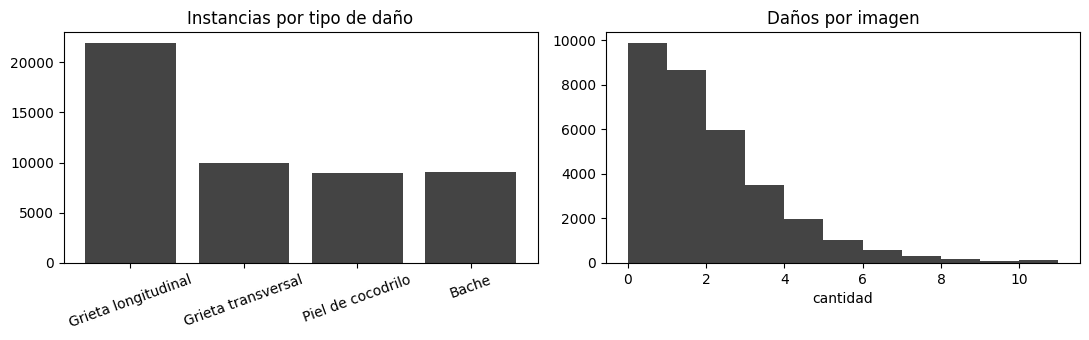

In [24]:
NOMBRES = {"D00": "Grieta longitudinal", "D10": "Grieta transversal", "D20": "Piel de cocodrilo", "D40": "Bache"}
df["n_obj"] = df.objs.apply(len)
for k in NOMBRES: df["n_" + k] = df.objs.apply(lambda o: sum(1 for a in o if a[0] == k))
eda = {"imagenes": int(len(df)), "sin_danio": int((df.n_obj == 0).sum()),
       "instancias_por_tipo": {NOMBRES[k]: int(df["n_" + k].sum()) for k in NOMBRES},
       "imagenes_con_bache": int((df.n_D40 > 0).sum()),
       "resoluciones": df.groupby(["W", "H"]).size().sort_values(ascending=False).head(3).to_dict().__str__()}
R["eda"] = eda; print(json.dumps(eda, indent=1, ensure_ascii=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(list(eda["instancias_por_tipo"].keys()), list(eda["instancias_por_tipo"].values()), color="#444")
ax[0].set_title("Instancias por tipo de daño"); ax[0].tick_params(axis="x", rotation=20)
ax[1].hist(df.n_obj, bins=range(0, 12), color="#444"); ax[1].set_title("Daños por imagen"); ax[1].set_xlabel("cantidad")
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_eda.png", dpi=150); plt.show()

## 3. Etiqueta de severidad (etiqueta débil)
RDD2022 marca **dónde** está el bache, no **qué tan grave** es. La severidad se calcula con una regla escrita antes de entrenar:

`puntaje = área del bache más grande / área de la imagen`, y se suma un 25 % por cada bache adicional (máximo 3).

Los cortes entre baja, media y alta son los terciles del puntaje **calculados solo con el conjunto de entrenamiento**, para no filtrar información de la prueba. Limitación conocida: el área depende de qué tan cerca se tomó la foto.

Imagenes con al menos un bache: 6000
{
 "train": {
  "n": 4200,
  "por_clase": {
   "baja": 1400,
   "media": 1400,
   "alta": 1400
  }
 },
 "val": {
  "n": 900,
  "por_clase": {
   "baja": 320,
   "media": 292,
   "alta": 288
  }
 },
 "test": {
  "n": 900,
  "por_clase": {
   "baja": 330,
   "media": 304,
   "alta": 266
  }
 }
}
Cortes: 0.020579559000666624 0.10533897666666668


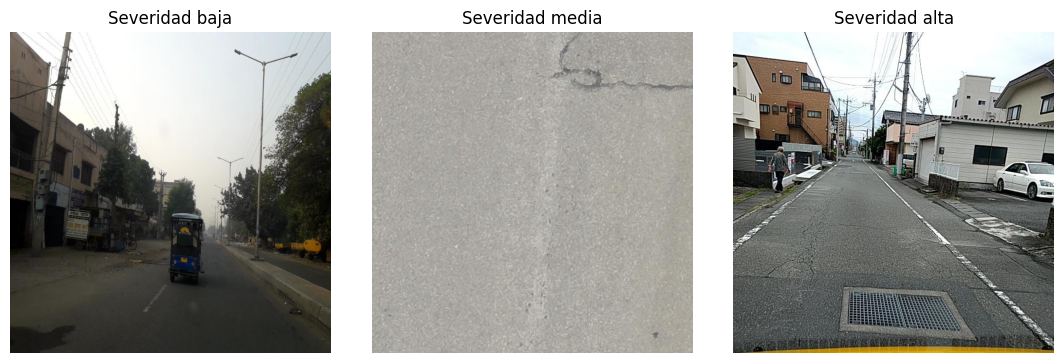

In [25]:
def puntaje(objs, W, H):
    a = sorted([(x2 - x1) * (y2 - y1) / (W * H) for (c, x1, y1, x2, y2) in objs if c == "D40"], reverse=True)
    if not a: return np.nan
    return a[0] * (1 + 0.25 * min(len(a) - 1, 3))
df["score"] = [puntaje(o, w, h) for o, w, h in zip(df.objs, df.W, df.H)]
b = df[df.score.notna() & df.img.notna()].reset_index(drop=True)
print("Imagenes con al menos un bache:", len(b))

# Division ANTES de cualquier transformacion (70 / 15 / 15), semilla fija
tr, tmp = train_test_split(b, test_size=0.30, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, random_state=SEED)
q1, q2 = tr.score.quantile([1/3, 2/3]).values           # cortes SOLO con train
def sev(s): return 0 if s <= q1 else (1 if s <= q2 else 2)
for d in (tr, va, te): d["y"] = d.score.apply(sev)
R["cortes_severidad"] = {"baja_media": float(q1), "media_alta": float(q2)}
R["division"] = {n: {"n": int(len(d)), "por_clase": {CLASES[i]: int((d.y == i).sum()) for i in range(3)}} for n, d in (("train", tr), ("val", va), ("test", te))}
print(json.dumps(R["division"], indent=1)); print("Cortes:", q1, q2)

fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
for i in range(3):
    r = tr[tr.y == i].iloc[0]; ax[i].imshow(cv2.cvtColor(cv2.imread(r.img), cv2.COLOR_BGR2RGB)); ax[i].set_title("Severidad " + CLASES[i]); ax[i].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/fig2_ejemplos.png", dpi=150); plt.show()

### Etiquetas manuales (opcional pero recomendado)
La celda exporta una muestra del conjunto de prueba a `resultados/para_etiquetar/` con un CSV. Si existe `etiquetas_manuales.csv` (columnas `archivo,severidad` con baja/media/alta) y la carpeta `fotos_propias/` con su CSV, el notebook también evalúa sobre ellas.

In [26]:
import shutil
os.makedirs(f"{OUT}/para_etiquetar", exist_ok=True)
m = te.sample(min(300, len(te)), random_state=SEED)
for p in m.img: shutil.copy(p, f"{OUT}/para_etiquetar/" + os.path.basename(p))
pd.DataFrame({"archivo": [os.path.basename(p) for p in m.img], "severidad": ""}).to_csv(f"{OUT}/para_etiquetar/plantilla_etiquetas.csv", index=False)
print("Muestra para etiquetar a mano:", len(m))

Muestra para etiquetar a mano: 300


## 4. Línea base: HOG + histograma de color + regresión logística

In [27]:
def leer(p, s=IMG):
    im = cv2.imread(p); im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB); return cv2.resize(im, (s, s))
def feats(p):
    im = leer(p, 128); g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
    h = hog(g, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
    c = np.concatenate([np.histogram(im[..., k], bins=16, range=(0, 255))[0] for k in range(3)]) / (128 * 128)
    return np.concatenate([h, c])
t0 = time.time()
Xtr = np.array([feats(p) for p in tr.img]); Xte = np.array([feats(p) for p in te.img])
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1, random_state=SEED))  # el escalador se ajusta solo con train
base.fit(Xtr, tr.y)
pred = {"Linea base (HOG + RL)": base.predict(Xte)}
print("Listo en", round(time.time() - t0), "s")

Listo en 57 s


## 5. Redes profundas

In [28]:
def ds(d, train=False):
    x = tf.data.Dataset.from_tensor_slices((d.img.values, d.y.values.astype("int32")))
    def f(p, y):
        im = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        return tf.image.resize(im, (IMG, IMG)), y
    if train: x = x.shuffle(len(d), seed=SEED)
    return x.map(f, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)
dtr, dva, dte = ds(tr, True), ds(va), ds(te)
aug = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomBrightness(0.15), layers.RandomContrast(0.15)], name="aumento")
cb = lambda: [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]
hist = {}

# --- Modelo 1: CNN propia desde cero ---
def bloque(x, f):
    x = layers.Conv2D(f, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization()(x); return layers.MaxPooling2D()(x)
i = keras.Input((IMG, IMG, 3)); x = aug(i); x = layers.Rescaling(1 / 255.)(x)
for f in (32, 64, 128, 256): x = bloque(x, f)
x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.4)(x)
cnn = keras.Model(i, layers.Dense(3, activation="softmax")(x), name="cnn_propia")
cnn.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
hist["CNN propia"] = cnn.fit(dtr, validation_data=dva, epochs=EP_CNN, callbacks=cb(), verbose=2).history
pred["CNN propia"] = cnn.predict(dte, verbose=0).argmax(1)

Epoch 1/12
132/132 - 48s - 364ms/step - accuracy: 0.3876 - loss: 1.2007 - val_accuracy: 0.3922 - val_loss: 1.1017
Epoch 2/12
132/132 - 46s - 351ms/step - accuracy: 0.4436 - loss: 1.0855 - val_accuracy: 0.3944 - val_loss: 1.0779
Epoch 3/12
132/132 - 11s - 84ms/step - accuracy: 0.4664 - loss: 1.0475 - val_accuracy: 0.3967 - val_loss: 1.1010
Epoch 4/12
132/132 - 10s - 75ms/step - accuracy: 0.4929 - loss: 1.0131 - val_accuracy: 0.4044 - val_loss: 1.1083
Epoch 5/12
132/132 - 10s - 75ms/step - accuracy: 0.5098 - loss: 0.9943 - val_accuracy: 0.4400 - val_loss: 1.0360
Epoch 6/12
132/132 - 9s - 65ms/step - accuracy: 0.5114 - loss: 0.9704 - val_accuracy: 0.4100 - val_loss: 1.0785
Epoch 7/12
132/132 - 11s - 84ms/step - accuracy: 0.5290 - loss: 0.9521 - val_accuracy: 0.4956 - val_loss: 1.1074
Epoch 8/12
132/132 - 11s - 83ms/step - accuracy: 0.5450 - loss: 0.9441 - val_accuracy: 0.5500 - val_loss: 0.9410
Epoch 9/12
132/132 - 11s - 84ms/step - accuracy: 0.5548 - loss: 0.9248 - val_accuracy: 0.4778 -

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/6
132/132 - 65s - 493ms/step - accuracy: 0.4636 - loss: 1.1475 - val_accuracy: 0.5622 - val_loss: 0.9420
Epoch 2/6
132/132 - 9s - 68ms/step - accuracy: 0.5383 - loss: 0.9927 - val_accuracy: 0.5822 - val_loss: 0.9116
Epoch 3/6
132/132 - 11s - 86ms/step - accuracy: 0.5633 - loss: 0.9419 - val_accuracy: 0.5800 - val_loss: 0.8795
Epoch 4/6
132/132 - 10s - 79ms/step - accuracy: 0.5710 - loss: 0.9125 - val_accuracy: 0.5656 - val_loss: 0.8812
Epoch 5/6
132/132 - 12s - 94ms/step - accuracy: 0.5843 - loss: 0.8920 - val_accuracy: 0.5822 - val_loss: 0.8628
Epoch 6/6
132/132 - 18s - 139ms/step - accuracy: 0.5890 - loss: 0.8849 - val_accuracy: 0.6000 - val_loss: 0.8578
Epoch 1/6
132/132 - 51s - 388ms/step - accuracy: 0.5436 - loss: 0.9718 - val_accuracy: 0.5978 - val_loss: 0.8589
Epoch 2/6
132/132 - 11s - 80ms/step - accuracy: 0.5771 - loss: 0.8978 - val_accuracy: 0.6089 - val_loss: 0.8552
Epoch 3/6
132/132 - 12s - 87ms/step - accuracy: 0.596

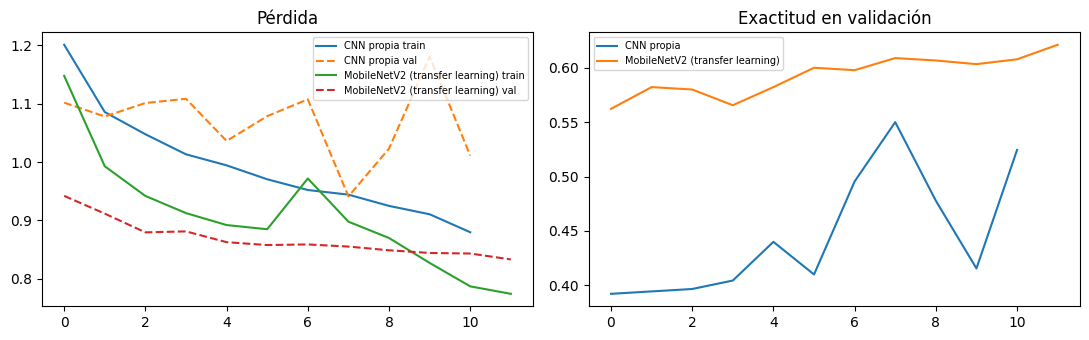

In [29]:
# --- Modelo 2: MobileNetV2 con transfer learning (2 fases) ---
try:
    mb = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights=None if SMOKE else "imagenet")
except Exception as e:
    print("Sin pesos de ImageNet:", e); mb = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights=None)
mb.trainable = False
i = keras.Input((IMG, IMG, 3)); x = aug(i); x = layers.Rescaling(1 / 127.5, offset=-1)(x)
x = mb(x, training=False); x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.3)(x)
tl = keras.Model(i, layers.Dense(3, activation="softmax")(x), name="mobilenetv2_tl")
tl.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = tl.fit(dtr, validation_data=dva, epochs=EP_TL1, callbacks=cb(), verbose=2).history       # fase 1: solo la cabeza
mb.trainable = True
for l in mb.layers[:-30]: l.trainable = False                                                  # fase 2: ajuste fino de las ultimas capas
tl.compile(keras.optimizers.Adam(1e-5), "sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = tl.fit(dtr, validation_data=dva, epochs=EP_TL2, callbacks=cb(), verbose=2).history
hist["MobileNetV2 (transfer learning)"] = {k: h1[k] + h2[k] for k in h1}
pred["MobileNetV2 (transfer learning)"] = tl.predict(dte, verbose=0).argmax(1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for n, h in hist.items():
    ax[0].plot(h["loss"], label=n + " train"); ax[0].plot(h["val_loss"], "--", label=n + " val"); ax[1].plot(h["val_accuracy"], label=n)
ax[0].set_title("Pérdida"); ax[1].set_title("Exactitud en validación"); ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/fig3_curvas.png", dpi=150); plt.show()
R["epocas"] = {n: len(h["loss"]) for n, h in hist.items()}

## 6. Resultados en el conjunto de prueba
Métrica principal: **recall de la clase alta** (el error más caro es dejar un bache grave al final de la cola) y **F1-macro**. Se agrega una referencia de "clase mayoritaria" para ver si los modelos aprenden algo.

                                 recall_alta  f1_macro  exactitud
Clase mayoritaria                      0.000     0.179      0.367
Linea base (HOG + RL)                  0.530     0.492      0.489
CNN propia                             0.782     0.513      0.530
MobileNetV2 (transfer learning)        0.647     0.583      0.578

Mejor modelo profundo: MobileNetV2 (transfer learning)
              precision    recall  f1-score   support

        baja       0.68      0.55      0.61       330
       media       0.46      0.54      0.50       304
        alta       0.63      0.65      0.64       266

    accuracy                           0.58       900
   macro avg       0.59      0.58      0.58       900
weighted avg       0.59      0.58      0.58       900



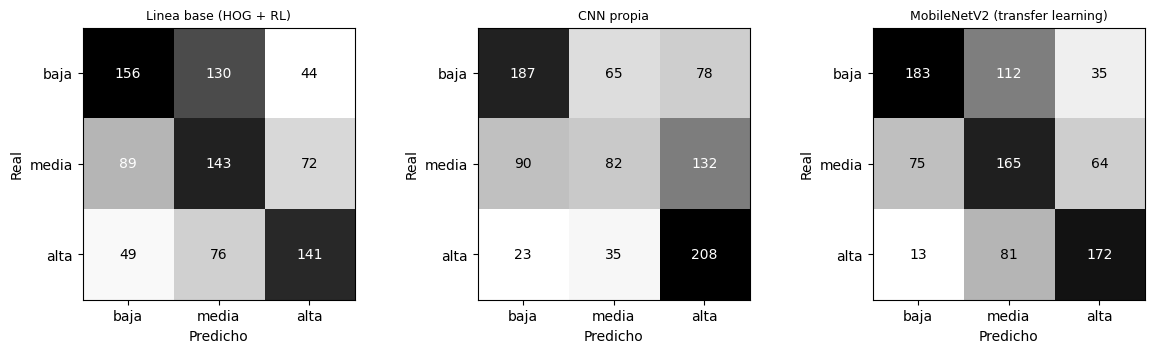

In [30]:
yte = te.y.values
pred["Clase mayoritaria"] = np.full_like(yte, np.bincount(tr.y).argmax())
def met(y, p): return {"recall_alta": round(float(recall_score(y, p, labels=[2], average="macro", zero_division=0)), 3),
                       "f1_macro": round(float(f1_score(y, p, average="macro", zero_division=0)), 3),
                       "exactitud": round(float(accuracy_score(y, p)), 3)}
orden = ["Clase mayoritaria", "Linea base (HOG + RL)", "CNN propia", "MobileNetV2 (transfer learning)"]
R["test"] = {n: met(yte, pred[n]) for n in orden}
R["matrices"] = {n: confusion_matrix(yte, pred[n], labels=[0, 1, 2]).tolist() for n in orden}
tabla = pd.DataFrame(R["test"]).T; print(tabla)
MEJOR = max(["CNN propia", "MobileNetV2 (transfer learning)"], key=lambda n: (R["test"][n]["f1_macro"], R["test"][n]["recall_alta"]))
R["mejor_modelo"] = MEJOR; modelo = cnn if MEJOR == "CNN propia" else tl
print("\nMejor modelo profundo:", MEJOR); print(classification_report(yte, pred[MEJOR], target_names=CLASES, zero_division=0))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, n in zip(ax, orden[1:]):
    cm = np.array(R["matrices"][n]); a.imshow(cm, cmap="Greys"); a.set_title(n, fontsize=9)
    a.set_xticks(range(3)); a.set_yticks(range(3)); a.set_xticklabels(CLASES); a.set_yticklabels(CLASES); a.set_xlabel("Predicho"); a.set_ylabel("Real")
    for r_ in range(3):
        for c_ in range(3): a.text(c_, r_, cm[r_, c_], ha="center", va="center", color="white" if cm[r_, c_] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig(f"{OUT}/fig4_matrices.png", dpi=150); plt.show()

In [31]:
# Evaluacion con etiquetas manuales y fotos propias, si existen
def evalua_csv(csv, carpeta, nombre):
    if not os.path.exists(csv): print("No hay", csv, "-> se omite"); return
    e = pd.read_csv(csv).dropna(); e = e[e.severidad.isin(CLASES)]
    X = np.array([leer(os.path.join(carpeta, a)) for a in e.archivo]).astype("float32")
    p = modelo.predict(X, verbose=0).argmax(1); y = e.severidad.map({c: i for i, c in enumerate(CLASES)}).values
    R[nombre] = dict(met(y, p), n=int(len(e)), matriz=confusion_matrix(y, p, labels=[0, 1, 2]).tolist()); print(nombre, R[nombre])
evalua_csv("etiquetas_manuales.csv", f"{OUT}/para_etiquetar", "test_manual")
# Las fotos propias de Bogotá se evalúan en la sección 11

No hay etiquetas_manuales.csv -> se omite
No hay fotos_propias/etiquetas.csv -> se omite


## 7. Explicabilidad: Grad-CAM

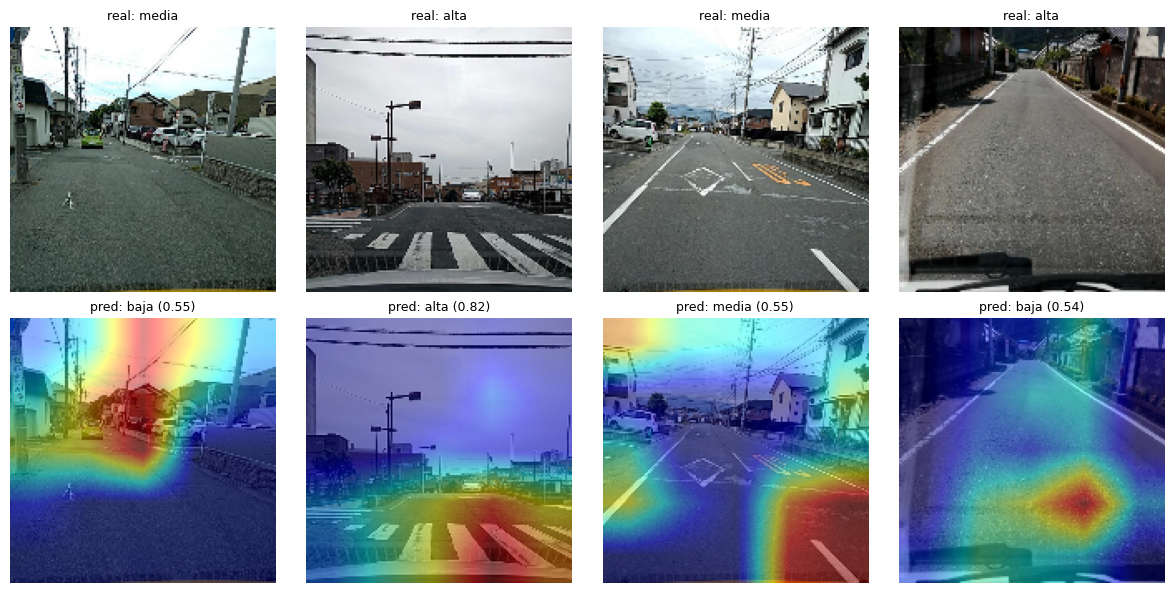

In [32]:
def ultima_conv(m):
    for l in reversed(m.layers):
        if isinstance(l, layers.Conv2D): return m, l.name
    return None, None
def gradcam(im):
    x = tf.convert_to_tensor(im[None].astype("float32"))
    if modelo.name == "cnn_propia":
        _, capa = ultima_conv(modelo); g = keras.Model(modelo.input, [modelo.get_layer(capa).output, modelo.output])
        with tf.GradientTape() as t:
            fm, p = g(x, training=False); k = tf.argmax(p[0]); s = p[:, k]
    else:
        with tf.GradientTape() as t:
            z = layers.Rescaling(1 / 127.5, offset=-1)(x); fm = mb(z, training=False); t.watch(fm)
            p = modelo.layers[-1](modelo.layers[-3](fm)); k = tf.argmax(p[0]); s = p[:, k]
    gr = t.gradient(s, fm); w = tf.reduce_mean(gr, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(fm * w[:, None, None, :], -1))[0].numpy()
    cam = cv2.resize(cam / (cam.max() + 1e-8), (IMG, IMG)); return cam, int(k), float(p[0, k])
def superpone(im, cam):
    h = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[..., ::-1]; return np.uint8(0.55 * im + 0.45 * h)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for j, (_, r) in enumerate(te.sample(4, random_state=SEED).iterrows()):
    im = leer(r.img); cam, k, pr = gradcam(im)
    ax[0, j].imshow(im); ax[0, j].set_title(f"real: {CLASES[r.y]}", fontsize=9); ax[0, j].axis("off")
    ax[1, j].imshow(superpone(im, cam)); ax[1, j].set_title(f"pred: {CLASES[k]} ({pr:.2f})", fontsize=9); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/fig5_gradcam.png", dpi=150); plt.show()

## 8. Análisis de errores (10 casos fallidos)

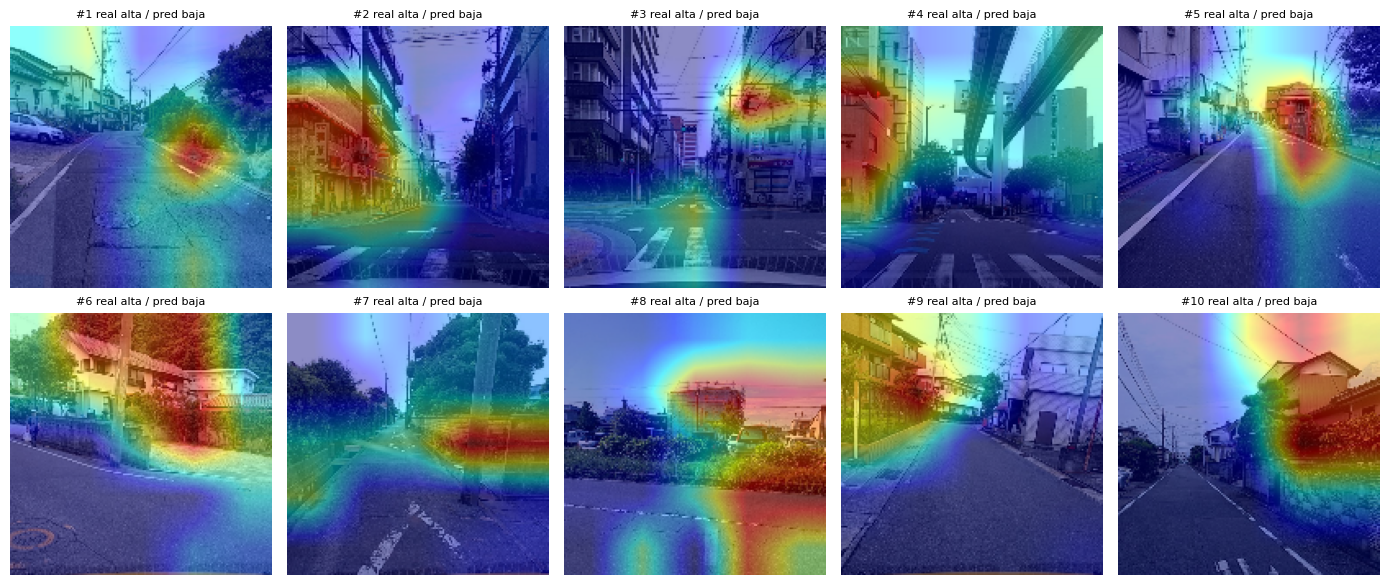

,caso,archivo,real,pred,puntaje_area,n_baches,otros_danios,brillo_medio,cerca_del_corte
0,1,022669.jpg,alta,baja,0.2558,3,1,117.8,False
1,2,035520.jpg,alta,baja,0.2306,3,0,87.3,False
2,3,009660.jpg,alta,baja,0.1797,2,1,98.7,False
3,4,033557.jpg,alta,baja,0.1595,2,0,92.7,False
4,5,027668.jpg,alta,baja,0.1559,1,3,111.4,False
5,6,017722.jpg,alta,baja,0.1495,3,2,116.0,False
6,7,032202.jpg,alta,baja,0.1374,1,3,93.3,False
7,8,012676.jpg,alta,baja,0.1374,1,1,131.4,False
8,9,006741.jpg,alta,baja,0.1371,1,1,117.5,False
9,10,014749.jpg,alta,baja,0.1354,1,0,117.0,False


In [33]:
te2 = te.copy(); te2["pred"] = pred[MEJOR]; mal = te2[te2.pred != te2.y].copy()
mal["dist"] = (mal.pred - mal.y).abs(); mal = mal.sort_values(["dist", "score"], ascending=[False, False]).head(10)
err = []
fig, ax = plt.subplots(2, 5, figsize=(14, 6)); ax = ax.ravel()
for j, (_, r) in enumerate(mal.iterrows()):
    im = leer(r.img); cam, _, _ = gradcam(im); bri = float(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY).mean())
    ax[j].imshow(superpone(im, cam)); ax[j].set_title(f"#{j+1} real {CLASES[r.y]} / pred {CLASES[r.pred]}", fontsize=8); ax[j].axis("off")
    err.append({"caso": j + 1, "archivo": os.path.basename(r.img), "real": CLASES[r.y], "pred": CLASES[r.pred], "puntaje_area": round(float(r.score), 4),
                "n_baches": int(r.n_D40), "otros_danios": int(r.n_obj - r.n_D40), "brillo_medio": round(bri, 1),
                "cerca_del_corte": bool(min(abs(r.score - q1), abs(r.score - q2)) < 0.15 * (q2 - q1 + 1e-9))})
for a in ax[len(mal):]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/fig6_errores.png", dpi=150); plt.show()
R["errores"] = err; R["tipo_error"] = {"subestima (pred < real)": int((te2.pred < te2.y).sum()), "sobreestima (pred > real)": int((te2.pred > te2.y).sum()), "alta_marcada_como_baja": int(((te2.y == 2) & (te2.pred == 0)).sum())}
pd.DataFrame(err)

## 9. Riesgo y reporte en lenguaje natural (componente NLP)
El riesgo de la plataforma combina la severidad visual con la posición que marca el ciudadano. El reporte para la entidad lo redacta un modelo de lenguaje (Transformer) a partir de una plantilla con los datos; si el modelo no carga, queda la plantilla. Se evalúan 10 reportes con una lista de chequeo.

In [34]:
REGLA = {("baja", "borde"): "Baja", ("baja", "carril"): "Media", ("media", "borde"): "Media", ("media", "carril"): "Alta", ("alta", "borde"): "Alta", ("alta", "carril"): "Crítico"}
def riesgo(sev, pos): return REGLA[(sev, pos)]
def plantilla(d):
    return (f"Reporte de daño vial. Tipo de daño: bache. Cantidad de baches detectados en la foto: {d['n']}. Severidad visual estimada por el modelo: {d['sev']} "
            f"(confianza {d['conf']:.0%}). Posición marcada por el ciudadano: {'carril de circulación' if d['pos'] == 'carril' else 'borde o berma'}. "
            f"Riesgo sugerido: {d['riesgo']}. La prioridad es una sugerencia automática y debe ser validada por una persona.")
gen = None
if not SMOKE:
    try:
        from transformers import pipeline
        gen = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct", device_map="auto")
    except Exception as e: print("No se pudo cargar el modelo de lenguaje:", e)
def redacta(d):
    base_txt = plantilla(d)
    if gen is None: return base_txt, "plantilla"
    msg = [{"role": "system", "content": "Eres un asistente que redacta reportes de daños viales para una entidad de mantenimiento vial en Colombia. Escribe en español, en un solo párrafo de máximo 90 palabras, tono formal y claro. Usa únicamente los datos entregados. No inventes direcciones, medidas ni fechas."},
           {"role": "user", "content": "Redacta el reporte con estos datos: " + base_txt}]
    try:
        o = gen(msg, max_new_tokens=160, do_sample=False)[0]["generated_text"][-1]["content"].strip(); return o, "modelo de lenguaje"
    except Exception as e: return base_txt, "plantilla"
def chequeo(txt, d):
    t = txt.lower()
    return {"menciona_severidad": d["sev"] in t, "menciona_riesgo": d["riesgo"].lower() in t, "menciona_posicion": ("carril" in t) if d["pos"] == "carril" else ("borde" in t or "berma" in t),
            "aclara_validacion_humana": any(w in t for w in ("validad", "validar", "persona", "revis", "verific")), "longitud_ok": len(txt.split()) <= 120}
reps = []
for j, (_, r) in enumerate(te.sample(10, random_state=7).iterrows()):
    im = leer(r.img); _, k, pr = gradcam(im); pos = "carril" if j % 2 == 0 else "borde"     # la posicion la marca el ciudadano; aqui se simula
    d = dict(n=int(r.n_D40), sev=CLASES[k], conf=pr, pos=pos); d["riesgo"] = riesgo(d["sev"], pos)
    txt, origen = redacta(d); ch = chequeo(txt, d); reps.append({"archivo": os.path.basename(r.img), **d, "origen": origen, "reporte": txt, "chequeo": ch, "puntos": int(sum(ch.values()))})
R["reportes"] = reps; R["reportes_resumen"] = {"origen": reps[0]["origen"], "promedio_puntos_de_5": round(float(np.mean([x["puntos"] for x in reps])), 2),
    "por_criterio": {k: int(sum(x["chequeo"][k] for x in reps)) for k in reps[0]["chequeo"]}}
print(json.dumps(R["reportes_resumen"], indent=1, ensure_ascii=False)); print("\nEjemplo:\n", reps[0]["reporte"])

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

{
 "origen": "modelo de lenguaje",
 "promedio_puntos_de_5": 3.4,
 "por_criterio": {
  "menciona_severidad": 10,
  "menciona_riesgo": 6,
  "menciona_posicion": 4,
  "aclara_validacion_humana": 4,
  "longitud_ok": 10
 }
}

Ejemplo:
 El reporte de daño vial indica que se han identificado 1 bache en la imagen, con una confianza de alta. Esta situación está considerada severa debido a su posibilidad de causar daños significativos al tráfico. El bache se encuentra en la carretera de circulación, y la prioridad es solicitar una recomendación automática. Una evaluación por parte de una persona será necesaria antes de tomar cualquier decisión.


## 10. Guardar todo

In [35]:
modelo.save(f"{OUT}/modelo_severidad.keras")
json.dump({"clases": CLASES, "img": IMG, "modelo": MEJOR}, open(f"{OUT}/config.json", "w"))
json.dump(R, open(f"{OUT}/resultados.json", "w"), indent=1, ensure_ascii=False)
with zipfile.ZipFile("resultados.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f"{OUT}/*.png") + [f"{OUT}/resultados.json", f"{OUT}/config.json", f"{OUT}/modelo_severidad.keras"]: z.write(f)
print("Listo. resultados.zip incluye el modelo, para no tener que reentrenar.")
try:
    from google.colab import files; files.download("resultados.zip")
except Exception: pass

Listo. Archivo para el informe: resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Prueba de campo con fotos propias de Bogotá
RDD2022 no tiene fotos de Colombia, así que aquí se prueba el modelo con fotos de calles de Bogotá. Sirven dos tipos de fotos:

- **El ZIP del inventario** (`100_Huecos_Bogota.zip`, generado por `descargar_huecos.py` a partir de `Inventario_Huecos_Bogota.xlsx`).
- **Fotos tomadas con el celular**, sueltas o en un ZIP. Se aceptan JPG, PNG, WEBP y BMP, y se corrige la rotación del celular (EXIF).

**Cómo se usa (dos pasadas):**
1. Ejecuta las dos celdas siguientes. Te pide subir el ZIP o las fotos. Como no hay etiquetas todavía, crea `etiquetas_bogota.csv` y una hoja con todas las fotos numeradas, **sin mostrar lo que predice el modelo** (para no sesgar el etiquetado).
2. Abre `etiquetas_bogota.csv` (panel de archivos a la izquierda → doble clic), llena la columna `severidad` con `baja`, `media` o `alta` según la Tabla II del informe, y si sabes dónde está el hueco llena `posicion` con `carril` o `borde`. Guarda (Ctrl+S) y vuelve a ejecutar la segunda celda.

Las fotos de prensa tienen derechos de autor: se usan solo para evaluar y **no se suben al repositorio**.

In [ ]:
# Configuración de la prueba de campo
CAMPO = "fotos_propias"              # carpeta donde quedan las fotos
ETIQUETAS = "etiquetas_bogota.csv"   # se crea sola en la primera pasada
ETIQUETAR_PRIMERO = True             # False = predecir sin etiquetas (solo para la demo, no cuenta como evaluación)
POSICION_POR_DEFECTO = "carril"      # si no se llena la columna posicion

In [ ]:
import os, io, glob, json, shutil, zipfile, unicodedata
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image, ImageOps
from sklearn.metrics import f1_score, recall_score, accuracy_score, confusion_matrix
OUT = globals().get("OUT", "resultados"); os.makedirs(OUT, exist_ok=True)
EXT = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

# --- 1) Traer las fotos ---------------------------------------------------------
def fotos_en(carpeta):
    return sorted(p for p in glob.glob(f"{carpeta}/**/*", recursive=True) if p.lower().endswith(EXT))
os.makedirs(CAMPO, exist_ok=True)
for z in glob.glob("*.zip"):                                   # ZIP arrastrado al panel de archivos
    if z != "resultados.zip" and not os.path.exists(z + ".listo"):
        with zipfile.ZipFile(z) as f: f.extractall(CAMPO)
        open(z + ".listo", "w").close(); print("Descomprimido:", z)
if not fotos_en(CAMPO):
    try:
        from google.colab import files
        print("Sube 100_Huecos_Bogota.zip o tus fotos (puedes seleccionar varias)...")
        for n in files.upload():
            if n.lower().endswith(".zip"):
                with zipfile.ZipFile(n) as f: f.extractall(CAMPO)
                open(n + ".listo", "w").close()
            else: shutil.move(n, os.path.join(CAMPO, n))
    except ImportError: pass
fotos = fotos_en(CAMPO)
assert fotos, f"No hay fotos en {CAMPO}/. Súbelas y vuelve a ejecutar."

# --- 2) Datos del inventario (localidad, fuente), si vienen -----------------------
log = glob.glob(f"{CAMPO}/**/descarga_log.csv", recursive=True)
base = os.path.dirname(log[0]) if log else CAMPO
meta = {}
if log:
    L = pd.read_csv(log[0], encoding="utf-8-sig")
    for _, r in L.iterrows():
        if isinstance(r["Archivo"], str) and r["Archivo"]:
            meta[os.path.normpath(r["Archivo"])] = {"id": r["ID"], "localidad": r["Localidad"]}
    print(f"Inventario: {len(meta)} fotos descargadas de {len(L)} filas")

# --- 3) Adaptar cada foto como en el entrenamiento ---------------------------------
CFGM = json.load(open(f"{OUT}/config.json")) if os.path.exists(f"{OUT}/config.json") else {}
CLASES = CFGM.get("clases", globals().get("CLASES", ["baja", "media", "alta"]))
IMG = CFGM.get("img", globals().get("IMG", 160))
def adaptar(p):
    """Abre cualquier formato, corrige la rotación del celular y deja RGB."""
    im = Image.open(p); im = ImageOps.exif_transpose(im).convert("RGB"); return im
def a_entrada(im):                       # mismo redimensionado que en el entrenamiento (tf.image.resize)
    return tf.image.resize(np.asarray(im, dtype="float32"), (IMG, IMG)).numpy()
filas, malas = [], []
for p in fotos:
    rel = os.path.normpath(os.path.relpath(p, base))
    try: im = adaptar(p)
    except Exception as e: malas.append((rel, str(e))); continue
    m = meta.get(rel, {})
    filas.append({"archivo": rel, "id": m.get("id", ""), "localidad": m.get("localidad", os.path.basename(os.path.dirname(rel)) if os.path.dirname(rel) else ""),
                  "ancho": im.size[0], "alto": im.size[1], "ruta": p})
C = pd.DataFrame(filas)
print(f"Fotos listas: {len(C)} | no se pudieron abrir: {len(malas)}")
for a, e in malas: print("   -", a, e)
peq = C[(C.ancho < 300) | (C.alto < 300)]
if len(peq): print(f"Ojo: {len(peq)} fotos miden menos de 300 px por lado; el resultado en esas es menos confiable.")

# --- 4) Etiquetas manuales -----------------------------------------------------------
def norm(t):
    t = unicodedata.normalize("NFKD", str(t)).encode("ascii", "ignore").decode().strip().lower()
    return {"b": "baja", "m": "media", "a": "alta", "borde": "borde", "berma": "borde", "c": "carril"}.get(t, t)
if not os.path.exists(ETIQUETAS):
    C[["archivo", "id", "localidad"]].assign(severidad="", posicion="").to_csv(ETIQUETAS, index=False, encoding="utf-8-sig")
    n = len(C); cols = 6; filas_g = int(np.ceil(n / cols))
    fig, ax = plt.subplots(filas_g, cols, figsize=(cols * 2.6, filas_g * 2.4)); ax = np.array(ax).ravel()
    for k, (_, r) in enumerate(C.iterrows()):
        ax[k].imshow(adaptar(r.ruta)); ax[k].set_title(r.archivo.replace(os.sep, "/")[-28:], fontsize=7); ax[k].axis("off")
    for a in ax[n:]: a.axis("off")
    plt.tight_layout(); plt.savefig("hoja_para_etiquetar.png", dpi=110); plt.show()
    print(f"\nCreado {ETIQUETAS} con {n} fotos y la hoja hoja_para_etiquetar.png.")
    print("Llena la columna severidad (baja/media/alta) y, si sabes, posicion (carril/borde). Guarda y vuelve a ejecutar esta celda.")
E = pd.read_csv(ETIQUETAS, encoding="utf-8-sig", dtype=str).fillna("")
E["archivo"] = E.archivo.apply(os.path.normpath); E["severidad"] = E.severidad.apply(norm); E["posicion"] = E.posicion.apply(norm)
C = C.merge(E[["archivo", "severidad", "posicion"]], on="archivo", how="left").fillna({"severidad": "", "posicion": ""})
C.loc[~C.severidad.isin(CLASES), "severidad"] = ""
etiquetadas = int((C.severidad != "").sum())
print(f"Fotos con severidad etiquetada: {etiquetadas} de {len(C)}")
if etiquetadas == 0 and ETIQUETAR_PRIMERO:
    raise SystemExit("Primero etiqueta las fotos (o pon ETIQUETAR_PRIMERO = False para solo predecir).")

# --- 5) Modelo (el de esta sesión o el guardado) -------------------------------------
if "modelo" not in globals():
    ruta_m = f"{OUT}/modelo_severidad.keras"
    assert os.path.exists(ruta_m), "No hay modelo en esta sesión. Ejecuta todo el notebook o sube resultados/modelo_severidad.keras."
    modelo = keras.models.load_model(ruta_m); print("Modelo cargado de", ruta_m)
X = np.stack([a_entrada(adaptar(p)) for p in C.ruta])
P = modelo.predict(X, verbose=0)
C["pred"] = [CLASES[i] for i in P.argmax(1)]; C["confianza"] = P.max(1).round(3)
for i, c in enumerate(CLASES): C["p_" + c] = P[:, i].round(3)
REGLA = {("baja", "borde"): "Baja", ("baja", "carril"): "Media", ("media", "borde"): "Media",
         ("media", "carril"): "Alta", ("alta", "borde"): "Alta", ("alta", "carril"): "Crítico"}
C["posicion_usada"] = C.posicion.where(C.posicion.isin(["carril", "borde"]), POSICION_POR_DEFECTO)
C["riesgo"] = [REGLA[(s, q)] for s, q in zip(C.pred, C.posicion_usada)]

# --- 6) Métricas contra las etiquetas manuales ----------------------------------------
R = globals().get("R") or (json.load(open(f"{OUT}/resultados.json")) if os.path.exists(f"{OUT}/resultados.json") else {})
idx = {c: i for i, c in enumerate(CLASES)}
L_ = C[C.severidad != ""]
campo = {"n_fotos": int(len(C)), "n_etiquetadas": int(len(L_)), "posicion_supuesta": int((~C.posicion.isin(["carril", "borde"])).sum()),
         "predicciones_por_clase": C.pred.value_counts().to_dict()}
if len(L_):
    y, p = L_.severidad.map(idx).values, L_.pred.map(idx).values
    campo.update({"recall_alta": round(float(recall_score(y, p, labels=[2], average="macro", zero_division=0)), 3),
                  "f1_macro": round(float(f1_score(y, p, average="macro", zero_division=0)), 3),
                  "exactitud": round(float(accuracy_score(y, p)), 3),
                  "matriz": confusion_matrix(y, p, labels=[0, 1, 2]).tolist(),
                  "etiquetas_reales_por_clase": L_.severidad.value_counts().to_dict(),
                  "alta_marcada_como_baja": int(((y == 2) & (p == 0)).sum())})
    if "test" in R and R.get("mejor_modelo") in R["test"]:
        t = R["test"][R["mejor_modelo"]]
        print(pd.DataFrame({"Prueba RDD2022 (n=900)": t, f"Bogotá (n={len(L_)})": {k: campo[k] for k in t}}))
    cm = np.array(campo["matriz"]); fig, a = plt.subplots(figsize=(3.6, 3.2)); a.imshow(cm, cmap="Greys")
    a.set_xticks(range(3)); a.set_yticks(range(3)); a.set_xticklabels(CLASES); a.set_yticklabels(CLASES); a.set_xlabel("Predicho"); a.set_ylabel("Real (etiqueta manual)")
    a.set_title(f"Bogotá (n = {len(L_)})", fontsize=10)
    for i in range(3):
        for j in range(3): a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout(); plt.savefig(f"{OUT}/fig8_bogota_matriz.png", dpi=150); plt.show()
    if len(L_) < 50: print(f"Ojo: con {len(L_)} fotos las métricas cambian mucho con cada acierto; repórtalas con ese tamaño de muestra.")
R["prueba_campo"] = campo; print(json.dumps(campo, indent=1, ensure_ascii=False))

# --- 7) Grad-CAM sobre fotos de Bogotá -------------------------------------------------
def gradcam_gen(x):
    nido = [l for l in modelo.layers if isinstance(l, keras.Model) and l.name.startswith("mobilenet")]
    objetivo = nido[0] if nido else [l for l in modelo.layers if isinstance(l, layers.Conv2D)][-1]
    x = tf.convert_to_tensor(x[None])
    with tf.GradientTape() as tape:
        h, fm = x, None
        for l in modelo.layers[1:]:
            h = l(h, training=False)
            if l is objetivo: fm = h; tape.watch(fm)
        k = int(tf.argmax(h[0])); s = h[:, k]
    g = tape.gradient(s, fm); w = tf.reduce_mean(g, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(fm * w[:, None, None, :], -1))[0].numpy()
    return cv2.resize(cam / (cam.max() + 1e-8), (IMG, IMG))
muestra = pd.concat([L_[L_.severidad != L_.pred], L_[L_.severidad == L_.pred], C[C.severidad == ""]]).head(12)
if len(muestra):
    cols = 4; fig, ax = plt.subplots(int(np.ceil(len(muestra) / cols)), cols, figsize=(13, 3.3 * np.ceil(len(muestra) / cols))); ax = np.array(ax).ravel()
    for k, (_, r) in enumerate(muestra.iterrows()):
        x = a_entrada(adaptar(r.ruta)); cam = gradcam_gen(x)
        hm = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[..., ::-1]
        ax[k].imshow(np.uint8(0.55 * x + 0.45 * hm)); ax[k].axis("off")
        ax[k].set_title(f"{r.localidad or r.archivo[-18:]}\nreal: {r.severidad or '?'} / pred: {r.pred} ({r.confianza:.2f})", fontsize=8)
    for a in ax[len(muestra):]: a.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT}/fig7_bogota_gradcam.png", dpi=150); plt.show()

# --- 8) Guardar ---------------------------------------------------------------------------
cols_out = ["archivo", "id", "localidad", "ancho", "alto", "severidad", "pred", "confianza"] + ["p_" + c for c in CLASES] + ["posicion_usada", "riesgo"]
C[cols_out].rename(columns={"severidad": "severidad_manual"}).to_csv(f"{OUT}/predicciones_bogota.csv", index=False, encoding="utf-8-sig")
json.dump(R, open(f"{OUT}/resultados.json", "w"), indent=1, ensure_ascii=False)
with zipfile.ZipFile("resultados.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f"{OUT}/*.png") + glob.glob(f"{OUT}/*.json") + glob.glob(f"{OUT}/*.csv") + [ETIQUETAS]:
        if os.path.exists(f): z.write(f)
print("Guardado: resultados/predicciones_bogota.csv y resultados.zip actualizado.")
try:
    from google.colab import files; files.download("resultados.zip")
except Exception: pass